# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Imroatul Bilad
- **Email:** imroatulbilad99@gmail.com
- **ID Dicoding:** 07Z6QL3MMZQR

## Menentukan Pertanyaan Bisnis

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Dataset *Bike Sharing* berisi catatan penyewaan sepeda selama dua tahun (2011-2012) dalam dua tingkat detail: ringkasan harian (`day.csv`) dan per jam (`hour.csv`). Pertanyaan bisnis berikut disusun dengan kerangka **SMART** (Specific, Measurable, Action-Oriented, Relevant, Time-bound) agar hasil analisis dapat langsung dipakai untuk keputusan operasional penyedia layanan sepeda.

- **Pertanyaan 1:** Bagaimana tren total penyewaan sepeda per bulan sepanjang Januari 2011 - Desember 2012, musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah, serta berapa persen pertumbuhan total penyewaan tahun 2012 dibandingkan 2011?
- **Pertanyaan 2:** Pada jam berapa puncak penyewaan sepeda terjadi pada hari kerja dibandingkan akhir pekan/hari libur selama 2011-2012, dan bagaimana perbedaan pola jam antara pengguna *casual* dan *registered*?
- **Pertanyaan 3:** Bagaimana pengaruh kondisi cuaca dan suhu terhadap rata-rata penyewaan sepeda harian selama 2011-2012, dan pada kondisi cuaca apa permintaan paling rendah?

**Keterangan SMART:**
- **Specific:** setiap pertanyaan fokus pada satu topik (tren & musim, pola jam, pengaruh cuaca).
- **Measurable:** dijawab dengan angka konkret (total penyewaan, rata-rata per hari/jam, persentase pertumbuhan, koefisien korelasi).
- **Action-Oriented:** jawabannya menjadi dasar penjadwalan ketersediaan armada, promosi musiman, dan jadwal perawatan.
- **Relevant:** sejalan dengan tujuan utama layanan *bike sharing*, yaitu menyesuaikan pasokan sepeda dengan pola permintaan.
- **Time-bound:** seluruh analisis dibatasi pada periode 1 Januari 2011 - 31 Desember 2012.

## Import Semua Packages/Library yang Digunakan

In [9]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load day_df

In [10]:
# Struktur submission menyimpan CSV di folder data/. Jika tidak ada (misalnya file
# diunggah langsung ke Colab), file dibaca dari folder kerja saat ini.
folder_data = "data" if os.path.exists("data/day.csv") else "."

day_df = pd.read_csv(f"{folder_data}/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load hour_df

In [11]:
hour_df = pd.read_csv(f"{folder_data}/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris dan 16 kolom (ringkasan harian 1 Januari 2011 - 31 Desember 2012), sedangkan `hour_df` berisi 17.379 baris dan 17 kolom (data per jam pada rentang yang sama).
- Struktur kedua tabel sama; `hour_df` hanya memiliki satu kolom tambahan, yaitu `hr` (jam 0-23).
- `cnt` adalah total penyewaan (`casual` + `registered`) dan menjadi variabel utama analisis.

### Assessing Data

#### Identifying tipe data, missing value, dan data duplikat

In [12]:
for nama, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"===== {nama} =====")
    df.info()
    print("Jumlah missing value :", df.isna().sum().sum())
    print("Jumlah data duplikat :", df.duplicated().sum())
    print()

===== day_df =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
Jumlah missing value : 0
Jumlah data duplikat : 0

===== hour_df =====
<cl

#### Identifying konsistensi antara day_df dan hour_df

In [13]:
print("Rentang tanggal day_df  :", day_df["dteday"].min(), "s/d", day_df["dteday"].max())
print("Rentang tanggal hour_df :", hour_df["dteday"].min(), "s/d", hour_df["dteday"].max())
print("Jumlah hari unik        :", day_df["dteday"].nunique(), "(day_df) |", hour_df["dteday"].nunique(), "(hour_df)")
print("Jumlah baris hour_df    :", len(hour_df), "| seharusnya 731 x 24 =", 731 * 24)

# casual + registered harus sama dengan cnt
print("\ncasual + registered == cnt (day_df)  :", (day_df["casual"] + day_df["registered"] == day_df["cnt"]).all())
print("casual + registered == cnt (hour_df) :", (hour_df["casual"] + hour_df["registered"] == hour_df["cnt"]).all())

# total cnt per hari pada hour_df harus sama dengan cnt pada day_df
total_dari_hour = hour_df.groupby("dteday")["cnt"].sum()
cocok = day_df.set_index("dteday")["cnt"].eq(total_dari_hour)
print("Hari dengan total jam == total harian :", cocok.sum(), "dari", len(cocok))

# jam yang tidak memiliki catatan pada hour_df
jam_lengkap = pd.MultiIndex.from_product([sorted(hour_df["dteday"].unique()), range(24)])
jam_ada = pd.MultiIndex.from_frame(hour_df[["dteday", "hr"]])
jam_hilang = jam_lengkap.difference(jam_ada)
hilang_per_jam = pd.Series([j[1] for j in jam_hilang], name="jumlah_jam_tanpa_catatan").value_counts().sort_index()
print("\nTotal jam tanpa catatan :", len(jam_hilang))
print("Jumlah per jam (hanya jam yang pernah hilang):")
print(hilang_per_jam.to_string())

Rentang tanggal day_df  : 2011-01-01 s/d 2012-12-31
Rentang tanggal hour_df : 2011-01-01 s/d 2012-12-31
Jumlah hari unik        : 731 (day_df) | 731 (hour_df)
Jumlah baris hour_df    : 17379 | seharusnya 731 x 24 = 17544

casual + registered == cnt (day_df)  : True
casual + registered == cnt (hour_df) : True
Hari dengan total jam == total harian : 731 dari 731

Total jam tanpa catatan : 165
Jumlah per jam (hanya jam yang pernah hilang):
jumlah_jam_tanpa_catatan
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3


#### Identifying nilai tidak wajar dan outlier

In [14]:
print("Hari dengan humidity = 0 pada day_df:")
print(day_df.loc[day_df["hum"] == 0, ["dteday", "hum", "temp", "weathersit", "cnt"]].to_string())
print("\nBaris dengan humidity = 0 pada hour_df:", (hour_df["hum"] == 0).sum(),
      "| tanggal:", list(hour_df.loc[hour_df["hum"] == 0, "dteday"].unique()))

print("\nDistribusi weathersit (day_df) :", day_df["weathersit"].value_counts().sort_index().to_dict())
print("Distribusi weathersit (hour_df):", hour_df["weathersit"].value_counts().sort_index().to_dict())

print("\nwindspeed = 0 :", (day_df["windspeed"] == 0).sum(), "baris (day_df) |",
      (hour_df["windspeed"] == 0).sum(), "baris (hour_df)")

def hitung_outlier(df, kolom):
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((df[kolom] < q1 - 1.5 * iqr) | (df[kolom] > q3 + 1.5 * iqr)).sum())

kolom_numerik = ["temp", "hum", "windspeed", "casual", "registered", "cnt"]
pd.DataFrame({
    "outlier_day_df": [hitung_outlier(day_df, k) for k in kolom_numerik],
    "outlier_hour_df": [hitung_outlier(hour_df, k) for k in kolom_numerik],
}, index=kolom_numerik)

Hari dengan humidity = 0 pada day_df:
        dteday  hum      temp  weathersit  cnt
68  2011-03-10  0.0  0.389091           3  623

Baris dengan humidity = 0 pada hour_df: 22 | tanggal: ['2011-03-10']

Distribusi weathersit (day_df) : {1: 463, 2: 247, 3: 21}
Distribusi weathersit (hour_df): {1: 11413, 2: 4544, 3: 1419, 4: 3}

windspeed = 0 : 0 baris (day_df) | 2180 baris (hour_df)


,outlier_day_df,outlier_hour_df
temp,0,0
hum,2,22
windspeed,13,342
casual,44,1192
registered,0,680
cnt,0,505


**Steps to Take:**
- Mengubah kolom `dteday` dari string menjadi datetime.
- Humidity bernilai 0 (1 hari pada `day_df` dan 22 jam pada `hour_df`, semuanya pada 10 Maret 2011) tidak wajar, sehingga diganti NaN lalu diisi dengan interpolasi linear.
- Mengubah kode numerik `season`, `yr`, `weekday`, dan `weathersit` menjadi label deskriptif, memperjelas nama kolom, serta menambah kolom `day_type` (Hari Kerja vs Akhir Pekan/Libur).
- Outlier tidak dihapus karena mencerminkan lonjakan permintaan yang nyata (terutama pengguna *casual* pada hari cerah/akhir pekan), bukan kesalahan input.
- 165 jam tanpa catatan pada `hour_df` tidak diimputasi: tidak ada indikasi kesalahan data, dan sebagian besar berada di dini hari sehingga diduga merupakan jam tanpa transaksi. Konsekuensinya, rata-rata per jam di dini hari bisa sedikit lebih tinggi dari kondisi sebenarnya.
- Suhu, humidity, dan windspeed dibiarkan dalam skala ternormalisasi (0-1) karena satuan aslinya tidak dijelaskan pada data.

**Insight:**
- Tidak ada missing value maupun data duplikat pada kedua tabel, sehingga kualitas dasar data baik.
- Data saling konsisten: `casual` + `registered` = `cnt` pada semua baris, dan total per hari dari `hour_df` sama dengan `cnt` pada `day_df` untuk seluruh 731 hari. Jadi hasil analisis dari kedua tabel akan selaras.
- `hour_df` hanya memiliki 17.379 dari 17.544 baris yang seharusnya (731 hari x 24 jam). Ada 165 jam tanpa catatan, 110 di antaranya pada jam 00-05.
- Nilai yang perlu diperhatikan: humidity 0 pada 10 Maret 2011; kondisi cuaca "hujan/salju lebat" (`weathersit` = 4) hanya 3 baris pada `hour_df` dan tidak ada pada `day_df`; `windspeed` = 0 pada 2.180 baris `hour_df` (tidak ada pada `day_df`), kemungkinan keterbatasan pengukuran.
- Outlier paling banyak ada pada `casual` (44 hari pada `day_df`, 1.192 jam pada `hour_df`), artinya penyewaan casual sangat fluktuatif. Pada `day_df`, `registered` dan `cnt` tidak memiliki outlier.

### Cleaning Data

#### Fixing tipe data dan nilai humidity yang tidak wajar

In [15]:
for df in (day_df, hour_df):
    # 1. dteday: object -> datetime
    df["dteday"] = pd.to_datetime(df["dteday"])
    # 2. humidity = 0 dianggap tidak wajar -> NaN -> diisi interpolasi linear
    df["hum"] = df["hum"].replace(0, np.nan).interpolate(method="linear")

print("Missing value setelah interpolasi :", day_df["hum"].isna().sum(), "(day_df) |", hour_df["hum"].isna().sum(), "(hour_df)")
print("Humidity minimum sekarang         :", round(day_df["hum"].min(), 3), "(day_df) |", round(hour_df["hum"].min(), 3), "(hour_df)")
print("Tipe data dteday                  :", day_df["dteday"].dtype, "|", hour_df["dteday"].dtype)
print()
print("Humidity 2011-03-10 setelah diperbaiki (day_df):", round(day_df.loc[day_df["dteday"] == "2011-03-10", "hum"].iloc[0], 4))

Missing value setelah interpolasi : 0 (day_df) | 0 (hour_df)
Humidity minimum sekarang         : 0.188 (day_df) | 0.08 (hour_df)
Tipe data dteday                  : datetime64[ns] | datetime64[ns]

Humidity 2011-03-10 setelah diperbaiki (day_df): 0.7125


#### Fixing nama kolom dan label kategorikal

In [16]:
nama_hari = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
nama_musim = {1: "Dingin", 2: "Semi", 3: "Panas", 4: "Gugur"}
nama_cuaca = {1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
nama_tahun = {0: 2011, 1: 2012}

urutan_musim = ["Dingin", "Semi", "Panas", "Gugur"]
urutan_cuaca = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan", "Hujan/Salju Lebat"]

for df in (day_df, hour_df):
    df.rename(columns={"dteday": "date", "yr": "year", "mnth": "month", "hr": "hour",
                       "hum": "humidity", "weathersit": "weather", "cnt": "total"}, inplace=True)
    df["season"] = df["season"].map(nama_musim)
    df["year"] = df["year"].map(nama_tahun)
    df["weekday"] = df["weekday"].map(nama_hari)
    df["weather"] = df["weather"].map(nama_cuaca)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")

print("Kolom day_df  :", list(day_df.columns))
print("Kolom hour_df :", list(hour_df.columns))
day_df.head()

Kolom day_df  : ['instant', 'date', 'season', 'year', 'month', 'holiday', 'weekday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'total', 'day_type']
Kolom hour_df : ['instant', 'date', 'season', 'year', 'month', 'hour', 'holiday', 'weekday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'total', 'day_type']


,instant,date,season,year,month,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,total,day_type
0,1,2011-01-01,Dingin,2011,1,0,Sabtu,0,Berkabut/Berawan,0.344167,0.363625,0.805833,0.160446,331,654,985,Akhir Pekan/Libur
1,2,2011-01-02,Dingin,2011,1,0,Minggu,0,Berkabut/Berawan,0.363478,0.353739,0.696087,0.248539,131,670,801,Akhir Pekan/Libur
2,3,2011-01-03,Dingin,2011,1,0,Senin,1,Cerah,0.196364,0.189405,0.437273,0.248309,120,1229,1349,Hari Kerja
3,4,2011-01-04,Dingin,2011,1,0,Selasa,1,Cerah,0.200000,0.212122,0.590435,0.160296,108,1454,1562,Hari Kerja
4,5,2011-01-05,Dingin,2011,1,0,Rabu,1,Cerah,0.226957,0.229270,0.436957,0.186900,82,1518,1600,Hari Kerja


**Insight:**
- `dteday` (kini `date`) bertipe datetime sehingga dapat dikelompokkan per bulan dan tahun.
- Humidity pada 10 Maret 2011 sudah diperbaiki (sekitar 0,71 pada `day_df`); tidak ada lagi nilai 0 maupun missing value.
- Label musim mengikuti kalender: kode 1 = Dingin, 2 = Semi, 3 = Panas, 4 = Gugur. Sebagian dokumentasi dataset menuliskan kode 1 sebagai *spring*, tetapi pada data kode 1 mencakup 21 Desember - 20 Maret (musim dingin belahan bumi utara), sehingga label disesuaikan dengan tanggal pada data.
- Kolom `year` kini berisi 2011/2012, `weekday` berisi nama hari, dan `weather` berisi deskripsi cuaca sehingga tabel dan grafik lebih mudah dibaca.

#### Menyimpan data bersih untuk dashboard

In [17]:
os.makedirs("dashboard", exist_ok=True)
day_df.to_csv("dashboard/main_data.csv", index=False)
hour_df.to_csv("dashboard/hour_data.csv", index=False)
print("Data bersih tersimpan di folder dashboard/:", os.listdir("dashboard"))

Data bersih tersimpan di folder dashboard/: ['main_data.csv', 'hour_data.csv']


## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif day_df dan hour_df

In [18]:
kolom_stat = ["temp", "atemp", "humidity", "windspeed", "casual", "registered", "total"]
print("Statistik deskriptif day_df:")
print(day_df[kolom_stat].describe().round(2).to_string())
print("\nStatistik deskriptif hour_df:")
print(hour_df[kolom_stat].describe().round(2).to_string())

Statistik deskriptif day_df:
         temp   atemp  humidity  windspeed   casual  registered    total
count  731.00  731.00    731.00     731.00   731.00      731.00   731.00
mean     0.50    0.47      0.63       0.19   848.18     3656.17  4504.35
std      0.18    0.16      0.14       0.08   686.62     1560.26  1937.21
min      0.06    0.08      0.19       0.02     2.00       20.00    22.00
25%      0.34    0.34      0.52       0.13   315.50     2497.00  3152.00
50%      0.50    0.49      0.63       0.18   713.00     3662.00  4548.00
75%      0.66    0.61      0.73       0.23  1096.00     4776.50  5956.00
max      0.86    0.84      0.97       0.51  3410.00     6946.00  8714.00

Statistik deskriptif hour_df:
           temp     atemp  humidity  windspeed    casual  registered     total
count  17379.00  17379.00  17379.00   17379.00  17379.00    17379.00  17379.00
mean       0.50      0.48      0.63       0.19     35.68      153.79    189.46
std        0.19      0.17      0.19       0.12

### Explore rekap penyewaan per tahun, musim, jenis hari, dan cuaca

In [19]:
rekap_tahun = day_df.groupby("year").agg(
    total_sewa=("total", "sum"),
    rata_harian=("total", "mean"),
    casual=("casual", "sum"),
    registered=("registered", "sum"),
).round(0)
print("Rekap per tahun:")
print(rekap_tahun.to_string())

print("\nRata-rata penyewaan harian per musim:")
print(day_df.groupby("season")["total"].agg(jumlah_hari="count", rata_harian="mean").reindex(urutan_musim).round(0).to_string())

print("\nRata-rata penyewaan harian per jenis hari:")
print(day_df.groupby("day_type")[["casual", "registered", "total"]].mean().round(0).to_string())

print("\nRata-rata penyewaan harian per kondisi cuaca:")
print(day_df.groupby("weather")["total"].agg(jumlah_hari="count", rata_harian="mean").reindex(urutan_cuaca).dropna().round(0).to_string())

print("\nProporsi pengguna casual vs registered (seluruh periode):")
print((day_df[["casual", "registered"]].sum() / day_df["total"].sum() * 100).round(1).to_string())

Rekap per tahun:
      total_sewa  rata_harian  casual  registered
year                                             
2011     1243103       3406.0  247252      995851
2012     2049576       5600.0  372765     1676811

Rata-rata penyewaan harian per musim:
        jumlah_hari  rata_harian
season                          
Dingin          181       2604.0
Semi            184       4992.0
Panas           188       5644.0
Gugur           178       4728.0

Rata-rata penyewaan harian per jenis hari:
                   casual  registered   total
day_type                                     
Akhir Pekan/Libur  1371.0      2959.0  4330.0
Hari Kerja          607.0      3978.0  4585.0

Rata-rata penyewaan harian per kondisi cuaca:
                    jumlah_hari  rata_harian
weather                                     
Cerah                     463.0       4877.0
Berkabut/Berawan          247.0       4036.0
Hujan/Salju Ringan         21.0       1803.0

Proporsi pengguna casual vs registered (selur

### Explore korelasi variabel numerik dengan total penyewaan

Korelasi terhadap total penyewaan (day_df):
registered    0.946
casual        0.673
atemp         0.631
temp          0.627
humidity     -0.116
windspeed    -0.235


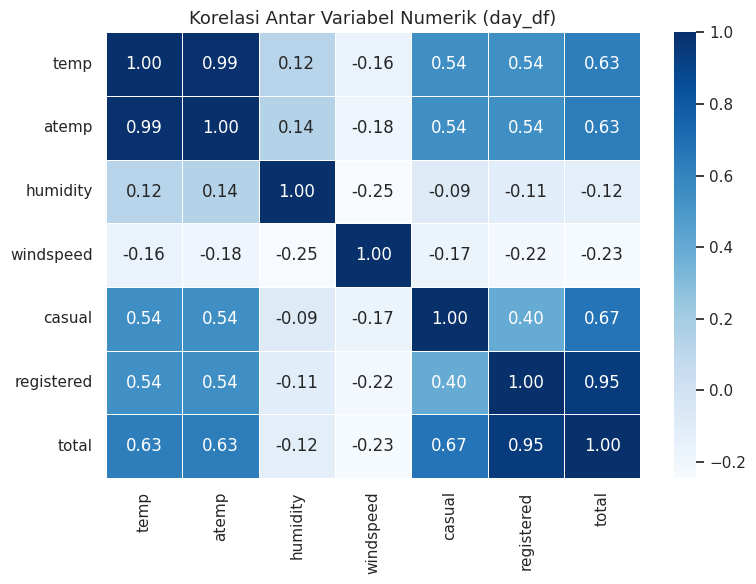

In [20]:
kolom_korelasi = ["temp", "atemp", "humidity", "windspeed", "casual", "registered", "total"]
korelasi = day_df[kolom_korelasi].corr()

print("Korelasi terhadap total penyewaan (day_df):")
print(korelasi["total"].drop("total").sort_values(ascending=False).round(3).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5)
plt.title("Korelasi Antar Variabel Numerik (day_df)", fontsize=13)
plt.tight_layout()
plt.show()

**Insight:**
- Rata-rata penyewaan harian sekitar 4.504 sepeda (minimum 22, maksimum 8.714), sedangkan rata-rata per jam sekitar 189 sepeda (maksimum 977).
- Pengguna *registered* menyumbang 81,2% dari seluruh penyewaan, sedangkan *casual* 18,8%.
- Rata-rata penyewaan harian naik dari 3.406 (2011) menjadi 5.600 (2012).
- Musim Panas memiliki rata-rata harian tertinggi (5.644) dan musim Dingin terendah (2.604).
- Hari kerja dan akhir pekan/libur memiliki rata-rata total yang mirip (4.585 vs 4.330), tetapi komposisinya berbeda: pengguna casual 1.371 per hari pada akhir pekan/libur vs 607 pada hari kerja.
- Rata-rata penyewaan menurun seiring memburuknya cuaca: Cerah 4.877, Berkabut/Berawan 4.036, Hujan/Salju Ringan 1.803.
- Suhu berkorelasi positif cukup kuat dengan total penyewaan (0,63), sedangkan windspeed (-0,24) dan humidity (-0,12) berkorelasi negatif lemah. Korelasi `registered` yang sangat tinggi (0,95) wajar karena kelompok ini adalah komponen terbesar dari total.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Tren bulanan, musim, dan pertumbuhan tahunan

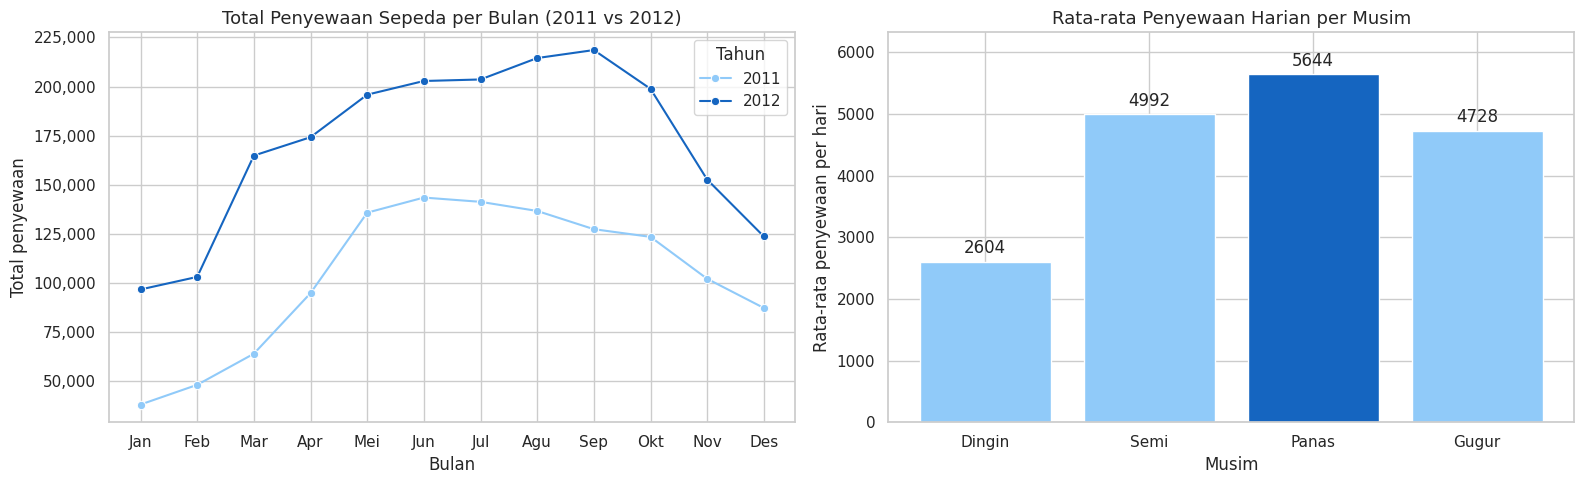

Total penyewaan 2011 : 1,243,103
Total penyewaan 2012 : 2,049,576
Pertumbuhan 2012 vs 2011 : 64.9%
Bulan tertinggi : Sep 2012 (218,573)
Bulan terendah  : Jan 2011 (38,189)
Musim tertinggi : Panas (5644/hari) | terendah: Dingin (2604/hari)
Selisih musim terendah vs tertinggi : -53.9%


In [21]:
bulanan = day_df.groupby(["year", "month"])["total"].sum().reset_index()
bulanan["year"] = bulanan["year"].astype(str)
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
rata_musim = day_df.groupby("season")["total"].mean().reindex(urutan_musim)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel kiri: tren bulanan 2011 vs 2012
sns.lineplot(data=bulanan, x="month", y="total", hue="year", marker="o",
             palette={"2011": "#90CAF9", "2012": "#1565C0"}, ax=axes[0])
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(nama_bulan)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[0].set_title("Total Penyewaan Sepeda per Bulan (2011 vs 2012)", fontsize=13)
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Total penyewaan")
axes[0].legend(title="Tahun")

# Panel kanan: rata-rata penyewaan harian per musim
warna = ["#1565C0" if v == rata_musim.max() else "#90CAF9" for v in rata_musim]
batang = axes[1].bar(rata_musim.index, rata_musim.values, color=warna)
axes[1].bar_label(batang, fmt="%.0f", padding=3)
axes[1].set_ylim(0, rata_musim.max() * 1.12)
axes[1].set_title("Rata-rata Penyewaan Harian per Musim", fontsize=13)
axes[1].set_xlabel("Musim")
axes[1].set_ylabel("Rata-rata penyewaan per hari")

plt.tight_layout()
plt.show()

total_2011 = day_df.loc[day_df["year"] == 2011, "total"].sum()
total_2012 = day_df.loc[day_df["year"] == 2012, "total"].sum()
bulan_max = bulanan.loc[bulanan["total"].idxmax()]
bulan_min = bulanan.loc[bulanan["total"].idxmin()]
print(f"Total penyewaan 2011 : {total_2011:,}")
print(f"Total penyewaan 2012 : {total_2012:,}")
print(f"Pertumbuhan 2012 vs 2011 : {(total_2012 / total_2011 - 1) * 100:.1f}%")
print(f"Bulan tertinggi : {nama_bulan[int(bulan_max['month']) - 1]} {bulan_max['year']} ({bulan_max['total']:,})")
print(f"Bulan terendah  : {nama_bulan[int(bulan_min['month']) - 1]} {bulan_min['year']} ({bulan_min['total']:,})")
print(f"Musim tertinggi : {rata_musim.idxmax()} ({rata_musim.max():.0f}/hari) | terendah: {rata_musim.idxmin()} ({rata_musim.min():.0f}/hari)")
print(f"Selisih musim terendah vs tertinggi : {(rata_musim.min() / rata_musim.max() - 1) * 100:.1f}%")

**Insight Pertanyaan 1:**
- Total penyewaan naik dari 1.243.103 (2011) menjadi 2.049.576 (2012), atau tumbuh **64,9%**. Setiap bulan pada 2012 berada di atas bulan yang sama pada 2011.
- Pola musiman jelas pada kedua tahun: penyewaan naik dari Januari, bertahan tinggi pada pertengahan tahun (Mei-September), lalu turun menuju Desember. Bulan tertinggi adalah September 2012 (218.573) dan terendah Januari 2011 (38.189). Pada 2011 puncak bulanan terjadi lebih awal, yaitu Juni (143.512).
- Musim Panas memiliki rata-rata penyewaan harian tertinggi (5.644), sedangkan musim Dingin terendah (2.604), sekitar 54% lebih rendah. Musim Semi (4.992) dan Gugur (4.728) berada di antaranya.

### Pertanyaan 2: Pola jam penyewaan (hari kerja vs akhir pekan, casual vs registered)

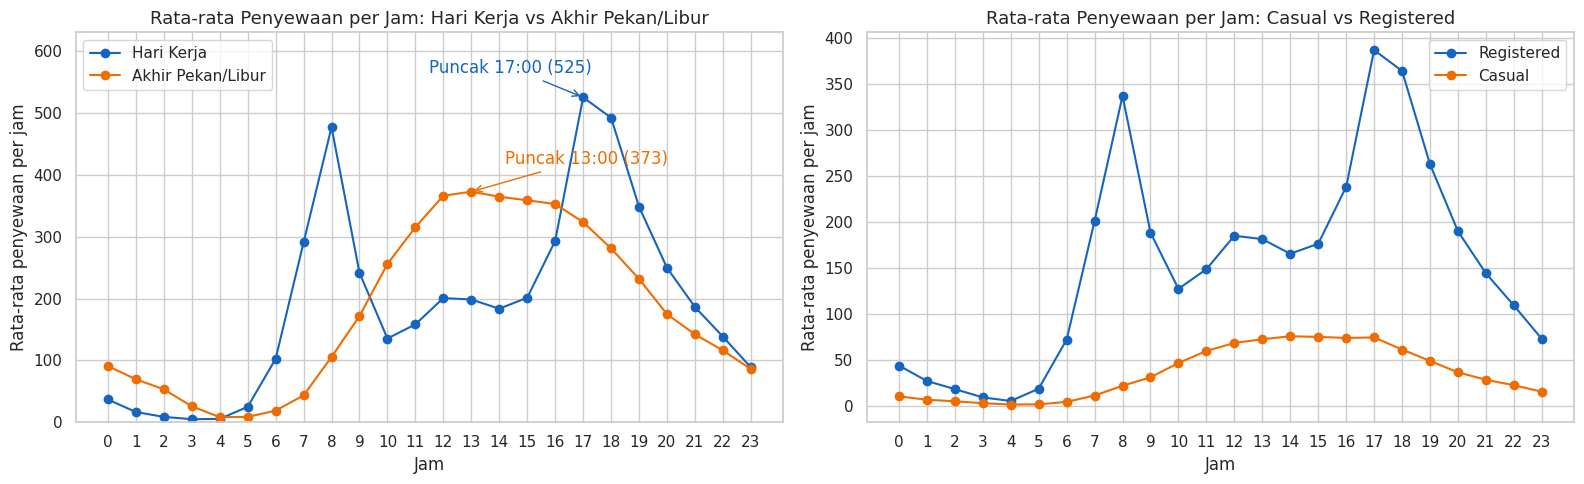

3 jam tersibuk (Akhir Pekan/Libur) : 13:00 (373), 12:00 (366), 14:00 (365)
3 jam tersibuk (Hari Kerja) : 17:00 (525), 18:00 (492), 08:00 (477)
Puncak registered : 17:00 (387) | puncak casual : 14:00 (76)

Porsi pengguna casual per jenis hari (%):
day_type
Akhir Pekan/Libur    31.7
Hari Kerja           13.2


In [22]:
pola_jam = hour_df.groupby(["day_type", "hour"])["total"].mean().reset_index()
pola_pengguna = hour_df.groupby("hour")[["casual", "registered"]].mean()
warna_tipe = {"Hari Kerja": "#1565C0", "Akhir Pekan/Libur": "#EF6C00"}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel kiri: rata-rata penyewaan per jam, hari kerja vs akhir pekan/libur
geser_label = {"Hari Kerja": (-5.5, 40), "Akhir Pekan/Libur": (1.2, 45)}
for tipe, warna in warna_tipe.items():
    grup = pola_jam[pola_jam["day_type"] == tipe]
    axes[0].plot(grup["hour"], grup["total"], marker="o", label=tipe, color=warna)
    puncak = grup.loc[grup["total"].idxmax()]
    dx, dy = geser_label[tipe]
    axes[0].annotate(f"Puncak {int(puncak['hour']):02d}:00 ({puncak['total']:.0f})",
                     xy=(puncak["hour"], puncak["total"]),
                     xytext=(puncak["hour"] + dx, puncak["total"] + dy),
                     arrowprops=dict(arrowstyle="->", color=warna), color=warna)
axes[0].set_ylim(0, pola_jam["total"].max() * 1.2)
axes[0].set_xticks(range(0, 24))
axes[0].set_title("Rata-rata Penyewaan per Jam: Hari Kerja vs Akhir Pekan/Libur", fontsize=13)
axes[0].set_xlabel("Jam")
axes[0].set_ylabel("Rata-rata penyewaan per jam")
axes[0].legend()

# Panel kanan: pola jam pengguna casual vs registered
axes[1].plot(pola_pengguna.index, pola_pengguna["registered"], marker="o", color="#1565C0", label="Registered")
axes[1].plot(pola_pengguna.index, pola_pengguna["casual"], marker="o", color="#EF6C00", label="Casual")
axes[1].set_xticks(range(0, 24))
axes[1].set_title("Rata-rata Penyewaan per Jam: Casual vs Registered", fontsize=13)
axes[1].set_xlabel("Jam")
axes[1].set_ylabel("Rata-rata penyewaan per jam")
axes[1].legend()

plt.tight_layout()
plt.show()

for tipe, grup in pola_jam.groupby("day_type"):
    top3 = grup.nlargest(3, "total")
    print(f"3 jam tersibuk ({tipe}) :", ", ".join(f"{int(r.hour):02d}:00 ({r.total:.0f})" for r in top3.itertuples()))
print(f"Puncak registered : {pola_pengguna['registered'].idxmax():02d}:00 ({pola_pengguna['registered'].max():.0f}) | puncak casual : {pola_pengguna['casual'].idxmax():02d}:00 ({pola_pengguna['casual'].max():.0f})")

porsi_casual = hour_df.groupby("day_type")[["casual", "total"]].sum()
print("\nPorsi pengguna casual per jenis hari (%):")
print((porsi_casual["casual"] / porsi_casual["total"] * 100).round(1).to_string())

**Insight Pertanyaan 2:**
- Pada **hari kerja** pola penyewaan memiliki dua puncak khas jam komuter. Puncak tertinggi pada pukul 17:00 (rata-rata 525 sewa/jam), disusul pukul 18:00 (492) dan pukul 08:00 (477).
- Pada **akhir pekan/hari libur** hanya ada satu puncak yang landai pada tengah hari, yaitu pukul 12:00-14:00 dengan puncak pukul 13:00 (373 sewa/jam), pola yang sesuai dengan penggunaan rekreasi.
- Pengguna **registered** mengikuti pola komuter (puncak pukul 08:00 dan 17:00; tertinggi pukul 17:00 sekitar 387 sewa/jam), sedangkan pengguna **casual** memiliki pola landai dengan puncak pukul 14:00 (sekitar 76 sewa/jam).
- Porsi pengguna casual mencapai 31,7% pada akhir pekan/libur, jauh lebih tinggi dibanding 13,2% pada hari kerja.

### Pertanyaan 3: Pengaruh cuaca dan suhu terhadap penyewaan

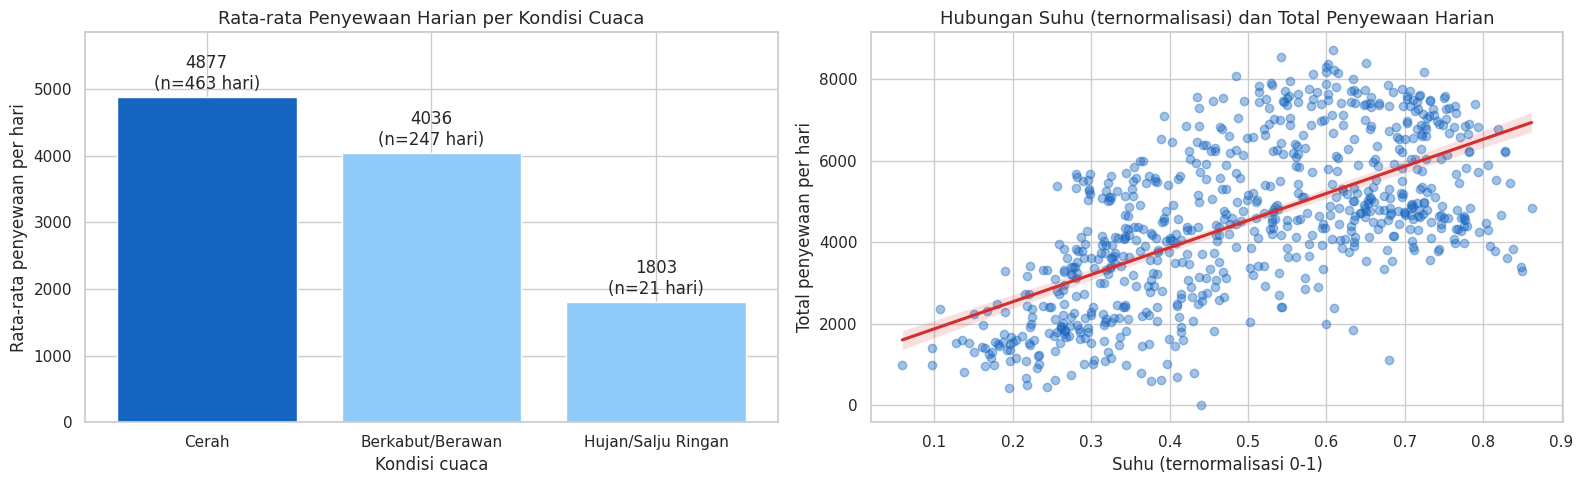

Rata-rata hari Cerah : 4877 | hari Hujan/Salju Ringan : 1803 | selisih : -63.0%
Rata-rata hari Berkabut/Berawan : 4036 | selisih vs Cerah : -17.2%

Korelasi dengan total penyewaan harian:
temp         0.627
humidity    -0.116
windspeed   -0.235


In [23]:
rata_cuaca = day_df.groupby("weather")["total"].agg(["mean", "count"]).reindex(urutan_cuaca).dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel kiri: rata-rata penyewaan harian per kondisi cuaca
warna = ["#1565C0" if v == rata_cuaca["mean"].max() else "#90CAF9" for v in rata_cuaca["mean"]]
batang = axes[0].bar(rata_cuaca.index, rata_cuaca["mean"], color=warna)
axes[0].bar_label(batang, labels=[f"{m:.0f}\n(n={int(n)} hari)" for m, n in zip(rata_cuaca["mean"], rata_cuaca["count"])], padding=3)
axes[0].set_ylim(0, rata_cuaca["mean"].max() * 1.2)
axes[0].set_title("Rata-rata Penyewaan Harian per Kondisi Cuaca", fontsize=13)
axes[0].set_xlabel("Kondisi cuaca")
axes[0].set_ylabel("Rata-rata penyewaan per hari")

# Panel kanan: hubungan suhu dan total penyewaan
sns.regplot(data=day_df, x="temp", y="total", scatter_kws={"alpha": 0.4, "color": "#1565C0"},
            line_kws={"color": "#D32F2F"}, ax=axes[1])
axes[1].set_title("Hubungan Suhu (ternormalisasi) dan Total Penyewaan Harian", fontsize=13)
axes[1].set_xlabel("Suhu (ternormalisasi 0-1)")
axes[1].set_ylabel("Total penyewaan per hari")

plt.tight_layout()
plt.show()

cerah = rata_cuaca.loc["Cerah", "mean"]
hujan = rata_cuaca.loc["Hujan/Salju Ringan", "mean"]
print(f"Rata-rata hari Cerah : {cerah:.0f} | hari Hujan/Salju Ringan : {hujan:.0f} | selisih : {(hujan / cerah - 1) * 100:.1f}%")
print(f"Rata-rata hari Berkabut/Berawan : {rata_cuaca.loc['Berkabut/Berawan', 'mean']:.0f} | selisih vs Cerah : {(rata_cuaca.loc['Berkabut/Berawan', 'mean'] / cerah - 1) * 100:.1f}%")
print("\nKorelasi dengan total penyewaan harian:")
print(day_df[["temp", "humidity", "windspeed"]].corrwith(day_df["total"]).round(3).to_string())

**Insight Pertanyaan 3:**
- Kondisi cuaca berpengaruh jelas: rata-rata penyewaan harian saat Cerah 4.877, Berkabut/Berawan 4.036 (17,2% lebih rendah), dan Hujan/Salju Ringan hanya 1.803 (63,0% lebih rendah). Permintaan paling rendah terjadi saat hujan/salju ringan. Perlu dicatat, kategori ini hanya diwakili 21 hari dan kategori hujan/salju lebat tidak muncul pada data harian, sehingga angkanya perlu ditafsirkan hati-hati.
- Suhu berkorelasi positif dengan total penyewaan (0,63): semakin hangat, semakin banyak sepeda disewa. Windspeed (-0,24) dan humidity (-0,12) berpengaruh negatif yang lebih lemah.
- Sebaran titik pada grafik cukup lebar, artinya suhu bukan satu-satunya faktor; musim, kenaikan permintaan pada 2012, dan jenis hari juga ikut berperan.

## Analisis Lanjutan (Opsional)

Analisis lanjutan menggunakan teknik **binning (manual grouping)**: jam dikelompokkan menjadi lima periode waktu pada `hour_df`, dan suhu ternormalisasi dikelompokkan menjadi empat kategori pada `day_df`.

Porsi penyewaan per periode waktu (%):
day_type           Akhir Pekan/Libur  Hari Kerja
time_group                                      
Dini Hari (00-05)                5.9         2.1
Pagi (06-09)                     7.8        24.1
Siang (10-15)                   47.0        23.4
Sore (16-19)                    27.4        36.1
Malam (20-23)                   11.9        14.4

Rata-rata penyewaan harian per kategori suhu:
                  jumlah_hari  rata_harian
temp_group                                
Dingin (<0.3)             135       2381.0
Sejuk (0.3-0.5)           232       4002.0
Hangat (0.5-0.7)          235       5584.0
Panas (>0.7)              129       5664.0


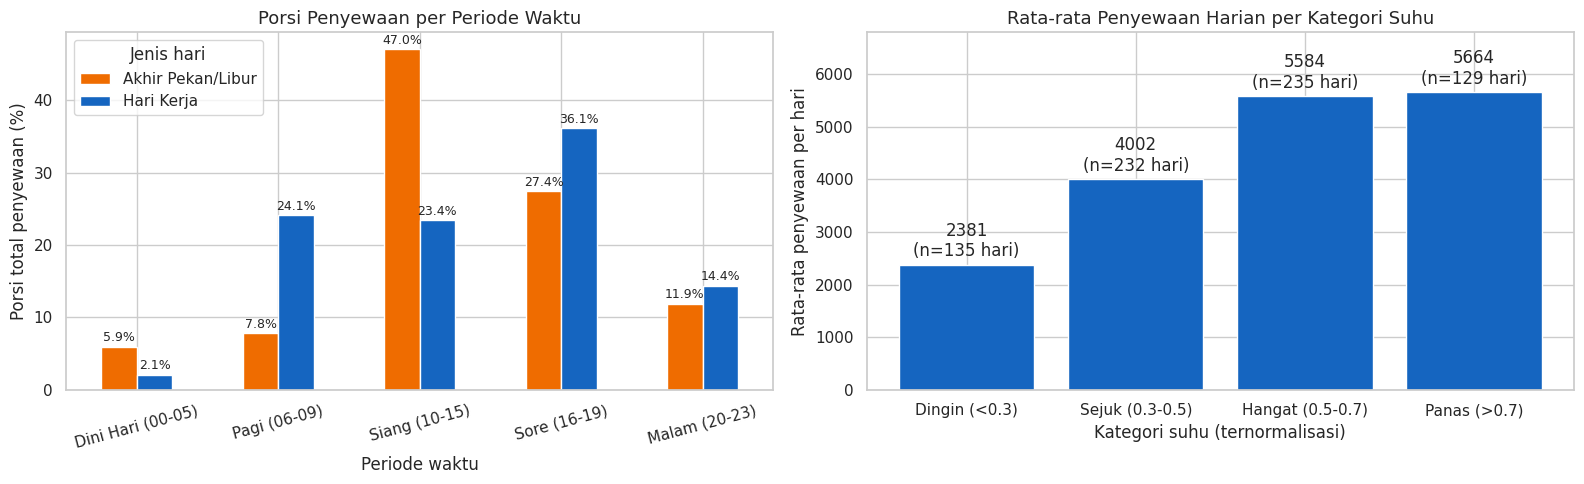

In [24]:
def kelompok_waktu(jam):
    if jam <= 5:
        return "Dini Hari (00-05)"
    elif jam <= 9:
        return "Pagi (06-09)"
    elif jam <= 15:
        return "Siang (10-15)"
    elif jam <= 19:
        return "Sore (16-19)"
    return "Malam (20-23)"

urutan_waktu = ["Dini Hari (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"]
hour_df["time_group"] = hour_df["hour"].apply(kelompok_waktu)

# Binning suhu (ternormalisasi) pada day_df
day_df["temp_group"] = pd.cut(day_df["temp"], bins=[0, 0.3, 0.5, 0.7, 1.0],
                              labels=["Dingin (<0.3)", "Sejuk (0.3-0.5)", "Hangat (0.5-0.7)", "Panas (>0.7)"],
                              include_lowest=True)

porsi_waktu = (pd.crosstab(hour_df["time_group"], hour_df["day_type"], values=hour_df["total"],
                           aggfunc="sum", normalize="columns").reindex(urutan_waktu) * 100).round(1)
rata_suhu = day_df.groupby("temp_group", observed=True)["total"].agg(jumlah_hari="count", rata_harian="mean").round(0)

print("Porsi penyewaan per periode waktu (%):")
print(porsi_waktu.to_string())
print("\nRata-rata penyewaan harian per kategori suhu:")
print(rata_suhu.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

porsi_waktu.plot(kind="bar", ax=axes[0], color=["#EF6C00", "#1565C0"], rot=15)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)
axes[0].set_title("Porsi Penyewaan per Periode Waktu", fontsize=13)
axes[0].set_xlabel("Periode waktu")
axes[0].set_ylabel("Porsi total penyewaan (%)")
axes[0].legend(title="Jenis hari")

batang = axes[1].bar(rata_suhu.index.astype(str), rata_suhu["rata_harian"], color="#1565C0")
axes[1].bar_label(batang, labels=[f"{v:.0f}\n(n={int(n)} hari)" for v, n in zip(rata_suhu["rata_harian"], rata_suhu["jumlah_hari"])], padding=3)
axes[1].set_ylim(0, rata_suhu["rata_harian"].max() * 1.2)
axes[1].set_title("Rata-rata Penyewaan Harian per Kategori Suhu", fontsize=13)
axes[1].set_xlabel("Kategori suhu (ternormalisasi)")
axes[1].set_ylabel("Rata-rata penyewaan per hari")

plt.tight_layout()
plt.show()

**Insight:**
- Pada hari kerja, pagi (06-09) dan sore (16-19) menyumbang 24,1% + 36,1% = 60,2% dari seluruh penyewaan hanya dalam 8 jam. Pada akhir pekan/libur, penyewaan terpusat pada siang (10-15) sebesar 47,0% dan sore (16-19) sebesar 27,4%.
- Dini hari (00-05) paling sepi, hanya 2,1% pada hari kerja dan 5,9% pada akhir pekan/libur.
- Rata-rata penyewaan harian naik tajam dari kategori suhu Dingin (2.381) ke Sejuk (4.002) dan Hangat (5.584), tetapi nyaris datar ke kategori Panas (5.664, hanya sekitar 1,4% lebih tinggi). Pada data ini, permintaan tampak tidak bertambah banyak lagi setelah suhu mencapai kategori hangat.
- Batas kategori suhu ditentukan secara manual pada skala ternormalisasi, dan jumlah hari tiap kategori tidak seimbang (129-235 hari), jadi hasilnya bersifat indikatif.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Permintaan penyewaan sepeda tumbuh 64,9% dari 2011 ke 2012 dan mengikuti pola musiman yang kuat. Penyewaan terendah terjadi pada awal tahun (Januari) dan musim Dingin (rata-rata 2.604 per hari), sedangkan tertinggi pada musim Panas (5.644 per hari) dengan puncak bulanan pada September 2012 (218.573).
- **Conclusion pertanyaan 2:** Pola jam sangat dipengaruhi jenis hari dan jenis pengguna. Hari kerja memiliki dua puncak komuter (pukul 08:00 dan 17:00-18:00, tertinggi pukul 17:00), sedangkan akhir pekan/libur memiliki satu puncak landai pada tengah hari (pukul 12:00-14:00). Pengguna registered mendominasi (81,2%) dan mengikuti pola komuter, sementara pengguna casual lebih banyak pada akhir pekan/libur (31,7% dari penyewaan) dan siang hari.
- **Conclusion pertanyaan 3:** Cuaca buruk dan suhu rendah menekan permintaan. Rata-rata penyewaan turun 17,2% saat berkabut/berawan dan 63,0% saat hujan/salju ringan dibanding hari cerah, dan suhu berkorelasi positif dengan total penyewaan (0,63). Analisis lanjutan menunjukkan kenaikan permintaan melambat setelah suhu mencapai kategori hangat.

**Rekomendasi Action Item:**
- **Siapkan armada untuk jam sibuk.** Pastikan ketersediaan sepeda maksimal pada pukul 07:00-09:00 dan 16:00-19:00 di hari kerja, dan pada pukul 11:00-15:00 di akhir pekan/libur. Jadwalkan perawatan armada pada dini hari (00:00-05:00) saat permintaan hanya 2-6% dari total.
- **Dorong casual menjadi registered.** Karena casual mencapai 31,7% penyewaan di akhir pekan/libur, tawarkan promo keanggotaan atau paket langganan pada siang hari akhir pekan agar pengguna casual beralih menjadi registered yang pemakaiannya lebih stabil.
- **Antisipasi musim dan cuaca.** Rencanakan kapasitas tertinggi pada Mei-Oktober, serta gunakan musim Dingin (Desember-Maret) untuk perawatan besar atau kampanye insentif. Saat prakiraan cuaca menunjukkan hujan, kurangi jumlah sepeda yang dikerahkan atau tawarkan promo untuk menjaga permintaan.
- **Gunakan prakiraan cuaca dalam perencanaan.** Masukkan suhu dan kondisi cuaca ke dalam perkiraan permintaan harian, karena keduanya terbukti berkaitan dengan jumlah penyewaan.
- **Pantau tren pertumbuhan.** Pertumbuhan 64,9% pada 2012 baru berdasar dua tahun data, jadi tinjau kembali dengan data periode berikutnya sebelum menetapkan target atau investasi armada jangka panjang.